In [ ]:
from evaluation_utils import *
RESULTS_PATH = os.path.join(RESULTS_DIR, "mc_maze_multitask_sac")

In [ ]:
# Use a plain string (no nested f-string/quotes). For an absolute path use four slashes.
storage_url = "sqlite:///" + RESULTS_PATH + "/optuna_study.db"
param_importances, study, idx_best_trial, idx_best_intermediate_trial = optuna_overview(
    storage_url, plot=True)

best_trial = get_trial_by_number(study.trials, idx_best_trial)
print("Parameters:")
for param in best_trial.params.keys():
    print(
        f"  {param} imp: {param_importances.get(param, tc.nan):.4f}, best: {best_trial.params.get(param)}")
#remove_pruned_trial_folders(study, RESULTS_PATH)

In [3]:
from src.evaluation.metrics.spike_stats import *
from src.models.mtf_sac_model import MTF_SAC_Model
from src.main import init_dataset
from evaluation_utils import *
GOAL_STATE = [0.0, 0.0]
T_DYNAMICS = 1
T_CONTROL = 80
RUN = "001"
DEVICE = tc.device("cpu")

In [4]:
observations_test = []
externals_test = []
for measurement_folder in ['20230425', '20210715', '20230404', '20210405', '20220930', '20210412', '20230320', '20210624', '20200317', '20230405', '20230508', '20220221']:
    spikes = np.load(DATA_DIR + f"/mc_multitask/{measurement_folder}_test/observations/1_spikes.pkl", allow_pickle=True)
    finger_position = np.load(DATA_DIR + f"/mc_multitask/{measurement_folder}_test/observations/2_finger_position.pkl", allow_pickle=True)
    observations_test.append(tc.cat([tc.as_tensor(np.concatenate(spikes)), tc.as_tensor(np.concatenate(finger_position))], dim=-1).float())
    targets = np.load(DATA_DIR + f"/mc_multitask/{measurement_folder}_test/externals/target_position.pkl", allow_pickle=True)
    externals_test.append(tc.as_tensor(np.concatenate(targets)).float())

In [ ]:
from src.models.dsr_model.FFN.base import FFN
# we edit the action to be amplified by a factor of 5, since the tanh squashes the action to be between -1 and 1, which turns out to be too small
amplification = 5
def sample_action(
    state: tc.Tensor,
    policy_params: nn.ModuleList,
    measurement_index: int,
    expected: bool = False,
) -> tc.Tensor:
    """Sample an action from the policy given the current state."""

    mean, log_std = FFN.forward(state, policy_params, model.dsr_sac_model.hyperparameters
    ).chunk(2, dim=-1)
    log_std = tc.clamp(log_std, -15, 19)
    if expected:
        u = mean
    else:
        noise = tc.randn_like(mean)
        u = mean + noise * log_std.exp()
    action = tc.tanh(u)
    normal = tc.distributions.Normal(mean, log_std.exp())
    loglikelihood = normal.log_prob(u)
    loglikelihood -= tc.log(1 - action.pow(2) + 1e-6)
    action = model.dsr_sac_model.project_action(
        action, measurement_index
    )*amplification
    if model.dsr_sac_model.use_state_dep_projection:
        action = model.dsr_sac_model.project_action_state_dep(action, state, measurement_index)
    loglikelihood = loglikelihood.sum(dim=-1, keepdim=True)
    return action, loglikelihood

def compute_projection_matrix(decoders) -> nn.ModuleList:
        """Compute the projection matrix on the null space of the decoder"""
        projection_matrix = nn.ModuleList()
        for measurement_index in range(len(model.dsr_sac_model.hyperparameters["goal_decoders"])):
            stacked_mean_weights = []
            stacked_mean_biases = []
            for goal_decoder in model.dsr_sac_model.hyperparameters["goal_decoders"][measurement_index] :
                decoder_name = goal_decoder["name"]
                control_dimensions = tc.as_tensor(goal_decoder["control_dimensions"])

                decoder = decoders[measurement_index][decoder_name]

                stacked_mean_weights.append(decoder.mean.weight[control_dimensions])
                stacked_mean_biases.append(decoder.mean.bias[control_dimensions])

            stacked_mean_weights = tc.cat(stacked_mean_weights, dim=0)
            stacked_mean_biases = tc.cat(stacked_mean_biases, dim=0)
            # compute null space of stacked_mean_weights using SVD
            U, S, Vh = tc.linalg.svd(stacked_mean_weights)
            null_space = Vh[S.size()[0]:, :].T
            projection_matrix_ = null_space @ null_space.T
            # bias must satisfy stacked_mean_weights @ bias + stacked_mean_biases = 0
            projection_bias = tc.linalg.lstsq(amplification*stacked_mean_weights, -stacked_mean_biases).solution
            linear = nn.Linear(Vh.shape[0], Vh.shape[0])
            # no gradient required
            linear.weight = nn.Parameter(projection_matrix_)
            linear.bias = nn.Parameter(projection_bias)
            linear.weight.requires_grad = False
            linear.bias.requires_grad = False
            # if action dim is provided, add projection as trainable matrix on lower subspace of null space
            if goal_decoder.get("action_dim", None) is not None:
                action_dim = goal_decoder["action_dim"]
                # projection needs to be of order action dim, but same size as projection_matrix_
                linear_2 = nn.Linear(Vh.shape[0], action_dim, bias=False)
                linear_3 = nn.Linear(action_dim, Vh.shape[0], bias=False)
                if not goal_decoder.get("state_dep_direction", False):
                    linear_2.weight.requires_grad = True
                    linear_3.weight.requires_grad = True
                else:
                    linear_2.weight.requires_grad = False
                    linear_3.weight.requires_grad = False
                projection_matrix.append(nn.Sequential(linear_2, linear_3, linear))
            else:
                projection_matrix.append(linear)
        return projection_matrix

## Evaluation

In [6]:
trial = get_trial_by_number(study.trials, 71)
trial_folder_name = "params_" + \
    "_".join([(f"{key}={ValueFormatter._formatted_value(value)}")
             for key, value in trial.params.items()])
print(trial_folder_name)

params_q_hid1=165_policy_hid1=83_env_steps_per_epoch=41_init_log_temp=-4p53_polyak_tau=0p00_pen=0p01_q_lr=0p01_policy_lr=0p00_q_lr_gamma=1p00_policy_lr_gamma=1p00_aq=23p26_apolicy=9p86_areg_q=3p26_areg_policy=0p93_q_hid2=149_policy_hid2=76


In [7]:
rewards = tc.zeros((5, 12))
runs = sorted(os.listdir(os.path.join(RESULTS_PATH, trial_folder_name)))

tc.manual_seed(1)
for k, run in enumerate(runs):
    run_path = os.path.join(RESULTS_PATH, trial_folder_name, run)
    parameters = json.load(open(f"{run_path}/config.json"))
    mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
    dataset = init_dataset(mtf_parameters, DEVICE)
    model = MTF_SAC_Model(dataset, model_path=run_path, device=DEVICE)
    MEASUREMENT_INDEX_TO_TS_INDEX = {dataset.evaluator_test_samples[i].measurement_index: dataset.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(dataset.evaluator_test_samples)-1, -1, -1)}

    
    model.dsr_sac_model.compute_projection_matrix = compute_projection_matrix
    model.dsr_sac_model.projection_matrix = model.dsr_sac_model.compute_projection_matrix(model.decoder_model.decoders)
    model.dsr_sac_model.sample_action = sample_action

        
    for measurement_index in range(12):
        cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
        
        for time_series_index in range(len(observations_test[measurement_index]) // 200):
            (trajectory,
            latent_trajectory,
            actions,
            decoded_actions,
            _,
            _,
            _,
            _) = model.generate_free_trajectory(
                observations_test[measurement_index],
                cumulative_timeseries_index,
                measurement_index,
                S=externals_test[measurement_index],
                t_start=time_series_index*200,
                T=200,
                expected=True,
                apply_actions=True
            )

            rewards[k, measurement_index] = model.reward_function(latent_trajectory[:, :-1], actions, measurement_index, expected=True).squeeze()[15:].mean().item()

Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936
SAC model parameters: 404212
Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936
SAC model parameters: 404212
Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936
SAC model parameters: 404212
Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936
SAC model parameters: 404212
Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936
SAC model parameters: 404212


In [ ]:
np.median(rewards, axis=1).mean(), np.median(rewards, axis=1).std()

(np.float32(-0.08980126), np.float32(0.0016695805))

## Analysis

In [8]:
# set up model
run_path = os.path.join(RESULTS_PATH, trial_folder_name, RUN)

parameters = json.load(open(f"{run_path}/config.json"))
mtf_parameters = json.load(open(f"{parameters["world_model"]["path"]}/config.json"))
dataset = init_dataset(mtf_parameters, DEVICE)
model = MTF_SAC_Model(dataset, model_path=run_path, device=DEVICE) 
MEASUREMENT_INDEX_TO_TS_INDEX = {dataset.evaluator_test_samples[i].measurement_index: dataset.evaluator_test_samples[i].cumulative_timeseries_index for i in range(len(dataset.evaluator_test_samples)-1, -1, -1)}


model.dsr_sac_model.compute_projection_matrix = compute_projection_matrix
model.dsr_sac_model.projection_matrix = model.dsr_sac_model.compute_projection_matrix(model.decoder_model.decoders)
model.dsr_sac_model.sample_action = sample_action

Sequence length set to 60.
Encoder model parameters: 316728
DSR model parameters: 38400
Decoder model parameters: 12936
SAC model parameters: 404212


In [9]:
trajectories_test = []
trajectories_test_with_actions = []
decoded_actions_test = []
actions_test = []
latent_trajectories_test_with_actions = []
latent_trajectories_test = []

for measurement_index in range(12):
    cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
    
    trajectories_test_ = []
    trajectories_test_with_actions_ = []
    decoded_actions_test_ = []
    actions_test_ = []
    latent_trajectories_test_with_actions_ = []
    latent_trajectories_test_ = []
    
    for time_series_index in range(len(observations_test[measurement_index]) // 200):
        (trajectory,
        latent_trajectory,
        actions,
        decoded_actions,
        _,
        _,
        _,
        _) = model.generate_free_trajectory(
            observations_test[measurement_index],
            cumulative_timeseries_index,
            measurement_index,
            S=externals_test[measurement_index],
            t_start=time_series_index*200,
            T=200,
            expected=False,
            expected_decoder=True,
            apply_actions=True
        )

        trajectories_test_with_actions_.append(trajectory[0, :-1].detach().cpu())
        actions_test_.append(actions[0].detach().cpu())
        decoded_actions_test_.append(decoded_actions[0].detach().cpu())
        latent_trajectories_test_with_actions_.append(latent_trajectory[0, :-1].detach().cpu())
            
        (trajectory,
        latent_trajectory,
        _,
        _,
        _,
        _,
        _,
        _) = model.generate_free_trajectory(
            observations_test[measurement_index],
            cumulative_timeseries_index,
            measurement_index,
            S=externals_test[measurement_index],
            t_start=time_series_index*200,
            T=200,
            expected=False,
            expected_decoder=True,
            apply_actions=False
        )
        trajectories_test_.append(trajectory[0, :-1].detach().cpu())
        latent_trajectories_test_.append(latent_trajectory[0, :-1].detach().cpu())
    
    trajectories_test.append(tc.cat(trajectories_test_, dim=0))
    trajectories_test_with_actions.append(tc.cat(trajectories_test_with_actions_, dim=0))
    decoded_actions_test.append(tc.cat(decoded_actions_test_, dim=0))
    actions_test.append(tc.cat(actions_test_, dim=0))
    latent_trajectories_test_with_actions.append(tc.cat(latent_trajectories_test_with_actions_, dim=0))
    latent_trajectories_test.append(tc.cat(latent_trajectories_test_, dim=0))

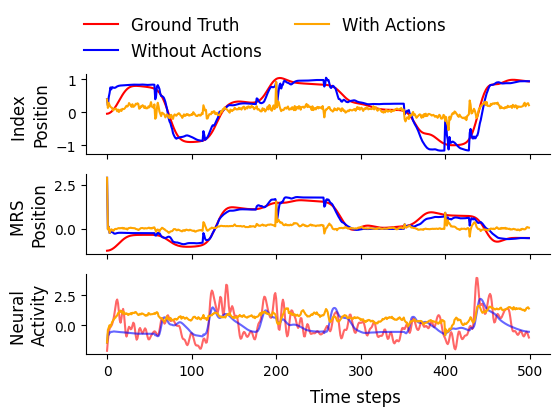

Figure saved to figures_new/sac_mc_multitask_example_trajectories_width_54_height_39.pdf


In [27]:
import matplotlib.lines as mlines

fig, axs = plt.subplots(figsize=(6, 4.8/5*4), nrows=3, ncols=1, sharex=True, sharey="row")
indices = np.array([74])#np.random.choice(trajectories_test[0][:, :-2].shape[1], 1, replace=False)

ax = axs[0]

ax.plot(observations_test[0][:500, -2], color='red', label='Ground Truth')
ax.plot(trajectories_test[0][:500, -2], color='blue', label='Without Actions')
ax.plot(trajectories_test_with_actions[0][:500, -2], color='orange', label='With Actions')
ax.set_ylabel('Index \nPosition', fontsize=FONT_SIZE)

ax = axs[1]
ax.plot(observations_test[0][:500, -1], color='red')
ax.plot(trajectories_test[0][:500, -1], color='blue')
ax.plot(trajectories_test_with_actions[0][:500, -1], color='orange')
ax.set_ylabel('MRS \nPosition', fontsize=FONT_SIZE)

        
ax = axs[2]
ax.plot(observations_test[0][:500, indices], alpha=0.6, color='red')
ax.plot(trajectories_test[0][:500, indices], color='blue', alpha=0.6)
ax.plot(trajectories_test_with_actions[0][:500, indices], color='orange')
ax.set_ylabel('Neural \nActivity', fontsize=FONT_SIZE)

# Create a single legend for the entire figure
legend_elements = [
    mlines.Line2D([0], [0], color='red', label='Ground Truth'),
    mlines.Line2D([0], [0], color='blue', label='Without Actions'),
    mlines.Line2D([0], [0], color='orange', label='With Actions'),
]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=FONT_SIZE, frameon=False, bbox_to_anchor=(0.5, 1.05), borderaxespad=0.)

fig.text(0.65, 0.04, 'Time steps', ha='center', va='center', fontsize=FONT_SIZE)
for ax in axs.flatten():
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
plt.tight_layout(rect=[0.05, 0.05, 1, 0.92])
plt.show()
save_fig(fig, "sac_mc_multitask_example_trajectories")

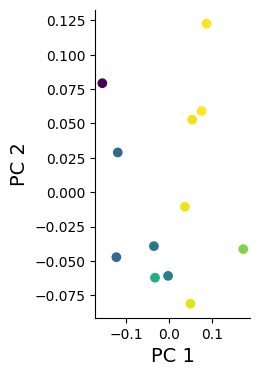

Figure saved to figures_new/sac_mc_multitask_subject_vectors_pca_width_24_height_35.pdf


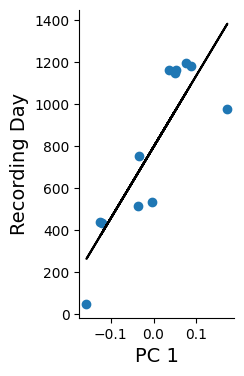

PearsonRResult(statistic=np.float64(0.8513533175928452), pvalue=np.float64(0.0004428775286034458))
Figure saved to figures_new/sac_mc_multitask_subject_vectors_corr_width_22_height_35.pdf


In [ ]:
import pandas as pd

days = []
for date in ['20230425', '20210715', '20230404', '20210405', '20220930', '20210412', '20230320', '20210624', '20200317', '20230405', '20230508', '20220221']:
    # extract date from filename which is the 6 digit number after "ses-"
    # format date from YYYYMMDD to YYYY-MM-DD
    date = f"{date[:4]}-{date[4:6]}-{date[6:]}"
    # days since first date
    day = (pd.to_datetime(date) - pd.to_datetime("2020-01-27")).days
    days.append(day)

pca = PCA(n_components=2)
subject_vectors = model.dsr_model.latent_step_params.subject_vectors.detach().cpu().numpy()
subject_vectors_2d = pca.fit_transform(subject_vectors)

# First plot
fig1, ax1 = plt.subplots(figsize=(2, 4))
ax1.scatter(subject_vectors_2d[:, 0], subject_vectors_2d[:, 1], c=days, cmap="viridis", label="Subject Vectors")
ax1.set_ylabel("PC 2", fontsize=FONT_SIZE)
ax1.set_xlabel("PC 1", fontsize=FONT_SIZE)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
plt.show()
#save_fig(fig1, "sac_mc_multitask_subject_vectors_pca")

# Second plot
fig2, ax2 = plt.subplots(figsize=(2, 4))
ax2.scatter(subject_vectors_2d[:, 0], days)
# draw regression line
m, b = np.polyfit(subject_vectors_2d[:, 0], days, 1)
ax2.plot(subject_vectors_2d[:, 0], m*subject_vectors_2d[:, 0] + b, color='black')
ax2.set_ylabel("Recording Day", fontsize=FONT_SIZE)
ax2.set_xlabel("PC 1", fontsize=FONT_SIZE)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
plt.show()

print(pearsonr(subject_vectors_2d[:, 0], days))
#save_fig(fig2, "sac_mc_multitask_subject_vectors_corr")

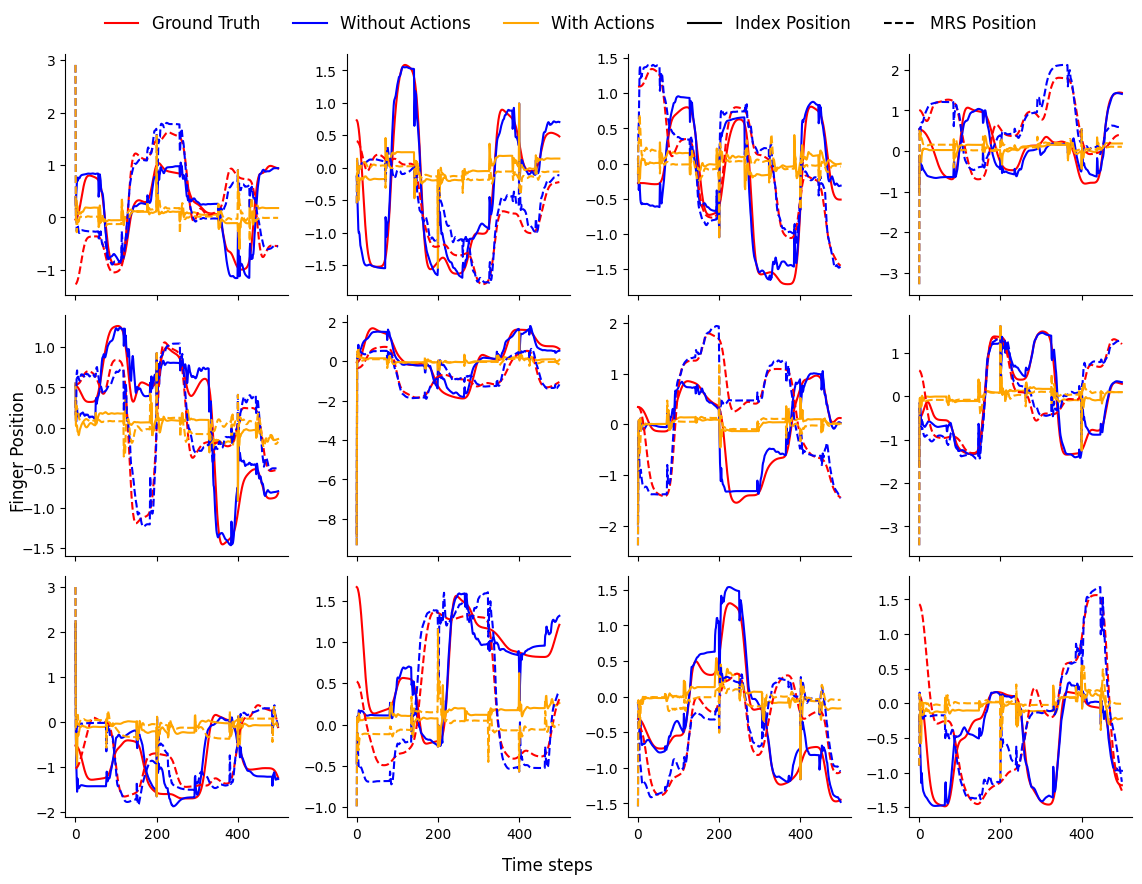

In [ ]:
FONT_SIZE = 12
fig, axs = plt.subplots(figsize=(12, 9), nrows=3, ncols=4, sharex=True)
axs = axs.flatten()

for i in range(12):
    ax = axs[i]
    
    # Plot Index and MRS positions in the same subplot
    ax.plot(observations_test[i][:500, -2], color='red', label='Ground Truth Index')
    ax.plot(trajectories_test[i][:500, -2], color='blue', label='Without Actions Index')
    ax.plot(trajectories_test_with_actions[i][:500, -2], color='orange', label='With Actions Index')
    
    ax.plot(observations_test[i][:500, -1], color='red', linestyle='--', label='Ground Truth MRS')
    ax.plot(trajectories_test[i][:500, -1], color='blue', linestyle='--', label='Without Actions MRS')
    ax.plot(trajectories_test_with_actions[i][:500, -1], color='orange', linestyle='--', label='With Actions MRS')
        
    # Remove top and right spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Create a single legend for the entire figure
import matplotlib.lines as mlines
legend_elements = [
    mlines.Line2D([0], [0], color='red', label='Ground Truth'),
    mlines.Line2D([0], [0], color='blue', label='Without Actions'),
    mlines.Line2D([0], [0], color='orange', label='With Actions'),
    mlines.Line2D([0], [0], color='black', linestyle='-', label='Index Position'),
    mlines.Line2D([0], [0], color='black', linestyle='--', label='MRS Position')
]
fig.legend(handles=legend_elements, loc='upper center', ncol=5, fontsize=FONT_SIZE, frameon=False)

fig.text(0.5, 0.04, 'Time steps', ha='center', va='center', fontsize=FONT_SIZE)
fig.text(0.06, 0.5, 'Finger Position', ha='center', va='center', rotation='vertical', fontsize=FONT_SIZE)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.96])
plt.show()
#save_fig(fig, "sac_mc_multitask_example_trajectories_combined")

### Drop Out Neurons

In [10]:
def compute_projection_matrix(decoders, drop_out_neurons) -> nn.ModuleList:
        """Compute the projection matrix on the null space of the decoder"""
        projection_matrix = nn.ModuleList()
        for measurement_index in range(len(model.dsr_sac_model.hyperparameters["goal_decoders"])):
            stacked_mean_weights = []
            stacked_mean_biases = []
            for goal_decoder in model.dsr_sac_model.hyperparameters["goal_decoders"][measurement_index] + [{'name': f'Gaussian_{measurement_index}', 'control_dimensions': drop_out_neurons}]:
                decoder_name = goal_decoder["name"]
                # TODO: rename to goal_dimensions
                control_dimensions = tc.as_tensor(goal_decoder["control_dimensions"])

                decoder = decoders[measurement_index][decoder_name]

                stacked_mean_weights.append(decoder.mean.weight[control_dimensions])
                stacked_mean_biases.append(decoder.mean.bias[control_dimensions])

            stacked_mean_weights = tc.cat(stacked_mean_weights, dim=0)
            stacked_mean_biases = tc.cat(stacked_mean_biases, dim=0)
            # compute null space of stacked_mean_weights using SVD
            U, S, Vh = tc.linalg.svd(stacked_mean_weights)
            null_space = Vh[S.size()[0]:, :].T
            projection_matrix_ = null_space @ null_space.T
            # bias must satisfy stacked_mean_weights @ bias + stacked_mean_biases = 0
            projection_bias = tc.linalg.lstsq(10*stacked_mean_weights, -stacked_mean_biases).solution
            linear = nn.Linear(Vh.shape[0], Vh.shape[0])
            # no gradient required
            linear.weight = nn.Parameter(projection_matrix_)
            linear.bias = nn.Parameter(projection_bias)
            linear.weight.requires_grad = False
            linear.bias.requires_grad = False
            # if action dim is provided, add projection as trainable matrix on lower subspace of null space
            if goal_decoder.get("action_dim", None) is not None:
                action_dim = goal_decoder["action_dim"]
                # projection needs to be of order action dim, but same size as projection_matrix_
                linear_2 = nn.Linear(Vh.shape[0], action_dim, bias=False)
                linear_3 = nn.Linear(action_dim, Vh.shape[0], bias=False)
                if not goal_decoder.get("state_dep_direction", False):
                    linear_2.weight.requires_grad = True
                    linear_3.weight.requires_grad = True
                else:
                    linear_2.weight.requires_grad = False
                    linear_3.weight.requires_grad = False
                projection_matrix.append(nn.Sequential(linear_2, linear_3, linear))
            else:
                projection_matrix.append(linear)
        return projection_matrix

model.dsr_sac_model.compute_projection_matrix = compute_projection_matrix

In [11]:
rewards_all_runs = np.zeros((13, 10, 12))
decoded_actions_test_all_runs = np.zeros((13, 10, 12, 98))
#drop_out_neuron_all_runs = []

for n_dropout_neurons in range(13):
    for i in range(10):
        drop_out_neurons = tc.randint(0, 94, (n_dropout_neurons,))
        #drop_out_neuron_all_runs.append(drop_out_neurons)
        model.dsr_sac_model.projection_matrix = model.dsr_sac_model.compute_projection_matrix(model.decoder_model.decoders, drop_out_neurons)
        
        trajectories_test_with_actions = []
        decoded_actions_test = []
        actions_test = []
        latent_trajectories_test_with_actions = []
        reward = []

        for measurement_index in range(12):
            cumulative_timeseries_index = MEASUREMENT_INDEX_TO_TS_INDEX[measurement_index]
            
            trajectories_test_ = []
            trajectories_test_with_actions_ = []
            decoded_actions_test_ = []
            actions_test_ = []
            latent_trajectories_test_with_actions_ = []
            latent_trajectories_test_ = []
            rewards_ = []
            
            for time_series_index in range(len(observations_test[measurement_index]) // 200):
                (trajectory,
                latent_trajectory,
                actions,
                decoded_actions,
                _,
                _,
                _,
                _) = model.generate_free_trajectory(
                    observations_test[measurement_index],
                    cumulative_timeseries_index,
                    measurement_index,
                    S=externals_test[measurement_index],
                    t_start=time_series_index*200,
                    T=200,
                    expected=True,
                    apply_actions=True
                )

                trajectories_test_with_actions_.append(trajectory[0, :-1].detach().cpu())
                actions_test_.append(actions[0].detach().cpu())
                decoded_actions_test_.append(decoded_actions[0].detach().cpu())
                latent_trajectories_test_with_actions_.append(latent_trajectory[0, :-1].detach().cpu())
                rewards_.append(model.reward_function(latent_trajectory[:, 1:].detach().cpu(), actions, 0, expected=True).detach().squeeze()[15:])
                
            trajectories_test_with_actions.append(tc.cat(trajectories_test_with_actions_, dim=0))
            actions_test.append(tc.cat(actions_test_, dim=0))
            latent_trajectories_test_with_actions.append(tc.cat(latent_trajectories_test_with_actions_, dim=0))
            
            rewards_all_runs[n_dropout_neurons, i, measurement_index] = tc.cat(rewards_, dim=0).mean().item()
            decoded_actions_test_all_runs[n_dropout_neurons, i, measurement_index] = tc.abs(tc.cat(decoded_actions_test_, dim=0)).mean(dim=0).detach().cpu()

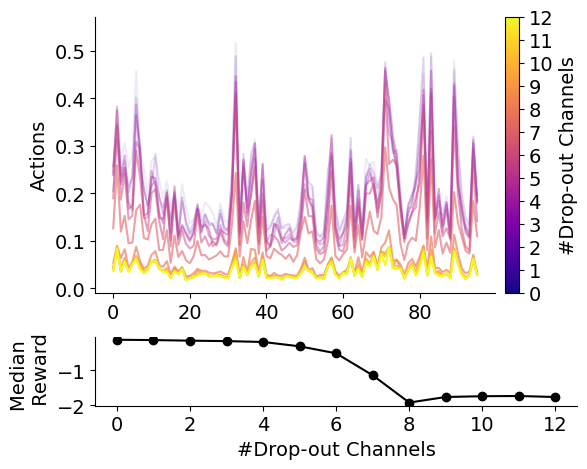

Figure saved to figures_new/sac_mc_multitask_action_drop_out_analysis_width_56_height_45.pdf


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

n_runs = decoded_actions_test_all_runs.shape[0]
run_indices = np.arange(n_runs)
action_means = [
    decoded_actions_test_all_runs[i, :, :, :96].mean(axis=(0, 1))
    for i in run_indices
]
rewards_median = np.median(rewards_all_runs.mean(1), axis=1)

fig, (ax_action, ax_reward) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(6, 4.8),
    gridspec_kw={"height_ratios": [2, 0.5]},
)

cmap = plt.get_cmap("plasma")
norm = Normalize(vmin=run_indices.min(), vmax=run_indices.max())
for i, action_mean in zip(run_indices, action_means):
    ax_action.plot(
        action_mean,
        color=cmap(norm(i)),
        linewidth=1.5,
        alpha=i / (n_runs - 1) ,
    )

ax_action.set_ylabel("Actions", fontsize=FONT_SIZE)
ax_action.tick_params(labelsize=FONT_SIZE)
ax_action.spines["top"].set_visible(False)
ax_action.spines["right"].set_visible(False)

colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_action,
    pad=0.02,
    ticks=run_indices,
)
colorbar.set_label("#Drop-out Channels", fontsize=FONT_SIZE)
colorbar.ax.tick_params(labelsize=FONT_SIZE)

ax_reward.plot(
    run_indices,
    rewards_median,
    color="black",
    marker="o",
    linewidth=1.5,
)
ax_reward.set_xlabel("#Drop-out Channels", fontsize=FONT_SIZE)
ax_reward.set_ylabel("Median \n Reward", fontsize=FONT_SIZE)
ax_reward.tick_params(labelsize=FONT_SIZE)
ax_reward.spines["top"].set_visible(False)
ax_reward.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()
save_fig(fig, "sac_mc_multitask_action_drop_out_analysis")

In [27]:
align_pdf_figures([
    FIG_DIR + "/sac_mc_multitask_subject_vectors_corr_width_22_height_35.pdf",
    FIG_DIR + "/sac_mc_multitask_example_trajectories_width_54_height_39.pdf",
    FIG_DIR + "/sac_mc_multitask_action_drop_out_analysis_width_56_height_45.pdf",
],
    output_pdf="combined_figures4.pdf",
    rows=1,
)

PosixPath('figures_new/combined_figures4.pdf')